# Homework 8: MLP with Pytorch
In this assignment, using Pytorch, you will need to build a simple fully-connected neural network (MLP) for predicting clothes category in the dataset FashionMNIST, which is part of the torchvision library.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets,transforms
import matplotlib.pyplot as plt

## Data Loading and Exploration 

For your convenience, I included the code for downloading both the train and test sets of the FashionMNIST data:

In [9]:
data=datasets.FashionMNIST(root='data',train=True,download=True,transform=transforms.ToTensor())

100%|██████████████████████████████████████| 26.4M/26.4M [00:02<00:00, 9.20MB/s]
100%|███████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 281kB/s]
100%|██████████████████████████████████████| 4.42M/4.42M [00:00<00:00, 4.75MB/s]
100%|██████████████████████████████████████| 5.15k/5.15k [00:00<00:00, 4.13MB/s]


In [11]:
test_data=datasets.FashionMNIST(root='data',train=False,download=True,transform=transforms.ToTensor())

Similar, to the MNIST for 10 digits, FashionMNIST contains 10 categories of clothes. The class/label encoding is summarized in the dictionary below:

In [14]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

What are the sizes of the train and test sets?

In [17]:
len(data), len(test_data)

(60000, 10000)

Divide the above set called 'data' into train data of size 54,000 and validation set of size 6,000. Hint: you have to first convert 'data' into list and then split it.

In [20]:
#Convert to list
data_list = list(data)

#Split into 54,000 train and 6,000 validation
train_list = data_list[:54000]
val_list   = data_list[54000:]

#Convert back to Dataset-like objects using TensorDataset
train_data = torch.utils.data.TensorDataset(
    torch.stack([x for x, y in train_list]),
    torch.tensor([y for x, y in train_list])
)

val_data = torch.utils.data.TensorDataset(
    torch.stack([x for x, y in val_list]),
    torch.tensor([y for x, y in val_list])
)

In [23]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=64, shuffle=False)

Unpack the first image in the train data and inspect it. What is the first dimension of the image? What are the height and width of the image?

In [26]:
img, label = train_data[0]   # unpack the first sample
print(img.shape)

torch.Size([1, 28, 28])


What is the label of this image?

In [28]:
img, label = train_data[0]
print(label)

tensor(9)


Plot this image:

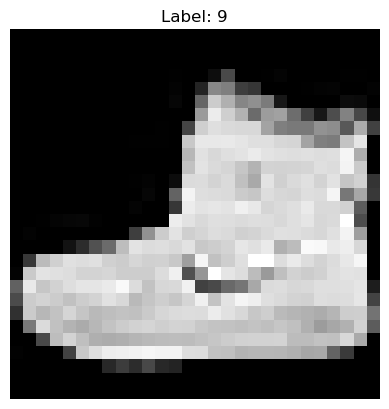

In [34]:
import matplotlib.pyplot as plt

img, label = train_data[0]

#remove the channel dimension for plotting
plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

Now, draw in one figure the first 3 images in the validation set. Hint: use img.squeeze() to remove the batch dimension.

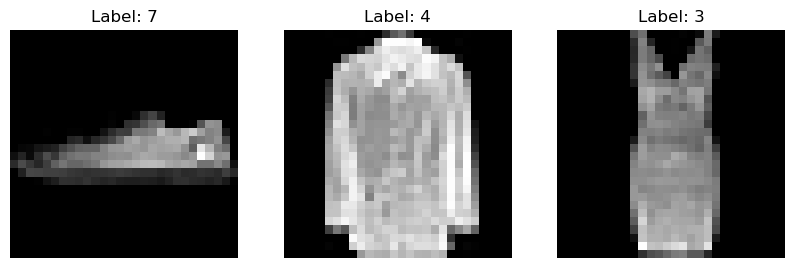

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,3))

for i in range(3):
    img, label = val_data[i]

    plt.subplot(1, 3, i+1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.show()

Create a dataloader for train data with batch size 1 and show its first element.

In [40]:
from torch.utils.data import DataLoader

# Create dataloader with batch size 1
train_loader_bs1 = DataLoader(train_data, batch_size=1, shuffle=False)

# Get first batch
first_batch = next(iter(train_loader_bs1))

images, labels = first_batch
print("Image shape:", images.shape)
print("Label:", labels.item())

Image shape: torch.Size([1, 1, 28, 28])
Label: 9


## Model 

Define a class for one-hidden-layer MLP model with arbitrary number of hidden nodes.

In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP(nn.Module):
    def __init__(self, hidden_size):
        super(MLP, self).__init__()
        
        # Input size = 28×28 = 784
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, hidden_size)   # hidden layer
        self.fc2 = nn.Linear(hidden_size, 10)    # output layer (10 classes)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

Create an instance of this class with 64 hidden nodes

In [45]:
model = MLP(hidden_size=64)
print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


How many parameters does this model have?

In [48]:
# Total number of parameters
total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)

# Optional: count only trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", trainable_params)

Total parameters: 50890
Trainable parameters: 50890


## Training
First, write a helper function that computes accuracy of the model on some data set:

In [54]:
def get_accuracy(model, data_loader, device='cpu'):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

Now, define a function 'train' that takes model, train and validation sets as inputs and outputs the training loss curve and accuracy curves (use the above get_accuracy function) for both train and validation sets. It should also return the trained model. 

In [56]:
def train(model, train_data, val_data, batch_size=54, lr=1e-3, num_epochs=5, device='cpu'):
    # Move model to device
    model.to(device)
    
    # DataLoaders
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_data, batch_size=batch_size, shuffle=False)
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Store metrics
    train_losses = []
    train_accs = []
    val_accs = []
    
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
        
        # Average loss over epoch
        epoch_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_loss)
        
        # Compute accuracies
        train_acc = get_accuracy(model, train_loader, device)
        val_acc = get_accuracy(model, val_loader, device)
        
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, "
              f"Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%")
    
    # Plot loss curve
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(train_losses, marker='o')
    plt.title("Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    
    # Plot accuracy curves
    plt.subplot(1,2,2)
    plt.plot(train_accs, marker='o', label='Train Acc')
    plt.plot(val_accs, marker='o', label='Val Acc')
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.show()
    
    return model, train_losses, train_accs, val_accs

Train for 5 epochs the above instance of MLP with 64 hidden units and plot training and accuracy curves with learning rate 0.005 and batch size 54

Epoch [1/5], Loss: 0.5179, Train Acc: 85.28%, Val Acc: 85.10%
Epoch [2/5], Loss: 0.3943, Train Acc: 86.99%, Val Acc: 86.15%
Epoch [3/5], Loss: 0.3630, Train Acc: 86.86%, Val Acc: 85.43%
Epoch [4/5], Loss: 0.3497, Train Acc: 87.54%, Val Acc: 86.28%
Epoch [5/5], Loss: 0.3307, Train Acc: 87.79%, Val Acc: 85.60%


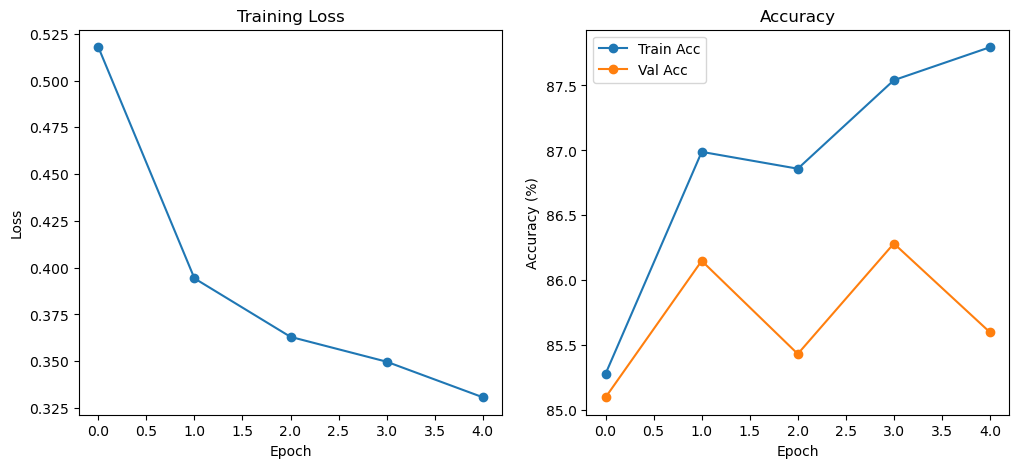

In [58]:
# Hyperparameters
batch_size = 54
lr = 0.005
num_epochs = 5
hidden_units = 64

# Create the model instance
model = MLP(hidden_size=hidden_units)

# Train the model
trained_model, train_losses, train_accs, val_accs = train(
    model,
    train_data,
    val_data,
    batch_size=batch_size,
    lr=lr,
    num_epochs=num_epochs
)

## Model Evaluation 

Get model accuracy on trained, validation and test data. Which one is higher and why? Does the model perform well, overall?

In [61]:
# Test DataLoader
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

# Compute accuracies
train_acc = get_accuracy(trained_model, DataLoader(train_data, batch_size=64))
val_acc   = get_accuracy(trained_model, DataLoader(val_data, batch_size=64))
test_acc  = get_accuracy(trained_model, test_loader)

print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

Train Accuracy: 87.79%
Validation Accuracy: 85.60%
Test Accuracy: 85.20%


# Train Accuracy = 87.79%
# This is the highest, which is expected because the model has seen this data during training and can fit it better.
# Validation Accuracy = 85.60%
# Test Accuracy = 85.20%
# Slightly lower than train accuracy, which is normal since these datasets contain unseen samples.
  
# The model has learned the patterns in the training data well, but it cannot perfectly generalize to new (validation/test) data.
# The small gap (~2–3%) between training and validation/test accuracy indicates mild overfitting, which is quite typical for a simple MLP.
  
# 85–87% accuracy on FashionMNIST with a one-hidden-layer MLP is good for a simple fully-connected network.
#  Not state-of-the-art (CNNs can reach >90%), but sufficient for demonstrating understanding of MLPs.
# The performance is consistent across validation and test sets, which shows that the model generalizes reasonably well.

## Saving and Reusing Model 

Save the weights of the above model

In [73]:
# Save model weights
torch.save(trained_model.state_dict(), "mlp_fashionmnist_weights.pth")

Create a new instance of this model and populate it with the saved weights

In [76]:
# 1. Recreate the model instance
new_model = MLP(hidden_size=64)

# 2. Load the saved weights
new_model.load_state_dict(torch.load("mlp_fashionmnist_weights.pth"))

# 3. Set the model to evaluation mode
new_model.eval()

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)

Using the new loaded model, predict the first two images in the test set and check if the predictions are correct

In [78]:
# Create a DataLoader for test set with batch size 1
test_loader = DataLoader(test_data, batch_size=1, shuffle=False)

# Get the first two batches
iterator = iter(test_loader)

for i in range(2):
    img, label = next(iterator)
    
    # Forward pass
    outputs = new_model(img)
    _, predicted = torch.max(outputs, 1)
    
    print(f"Image {i+1}:")
    print(f"True label: {label.item()} ({labels_map[label.item()]})")
    print(f"Predicted: {predicted.item()} ({labels_map[predicted.item()]})")
    print(f"Correct? {'Yes' if predicted.item() == label.item() else 'No'}\n")

Image 1:
True label: 9 (Ankle Boot)
Predicted: 9 (Ankle Boot)
Correct? Yes
Image 2:
True label: 2 (Pullover)
Predicted: 2 (Pullover)
Correct? Yes


## Changing batch size, learning rate and epochs

Now train the same model MLP(64) for 10 epochs with bigger batch size, e.g. 256, and higher learning rate, e.g. 0.01. Does this lead to a better result? Is there overfitting?

Epoch [1/10], Loss: 0.5526, Train Acc: 85.64%, Val Acc: 84.93%
Epoch [2/10], Loss: 0.4015, Train Acc: 87.09%, Val Acc: 86.15%
Epoch [3/10], Loss: 0.3674, Train Acc: 87.72%, Val Acc: 86.22%
Epoch [4/10], Loss: 0.3447, Train Acc: 88.16%, Val Acc: 86.87%
Epoch [5/10], Loss: 0.3240, Train Acc: 88.50%, Val Acc: 86.55%
Epoch [6/10], Loss: 0.3167, Train Acc: 88.68%, Val Acc: 87.03%
Epoch [7/10], Loss: 0.3030, Train Acc: 87.98%, Val Acc: 85.48%
Epoch [8/10], Loss: 0.2987, Train Acc: 88.71%, Val Acc: 86.03%
Epoch [9/10], Loss: 0.2937, Train Acc: 89.62%, Val Acc: 87.25%
Epoch [10/10], Loss: 0.2863, Train Acc: 89.74%, Val Acc: 87.75%


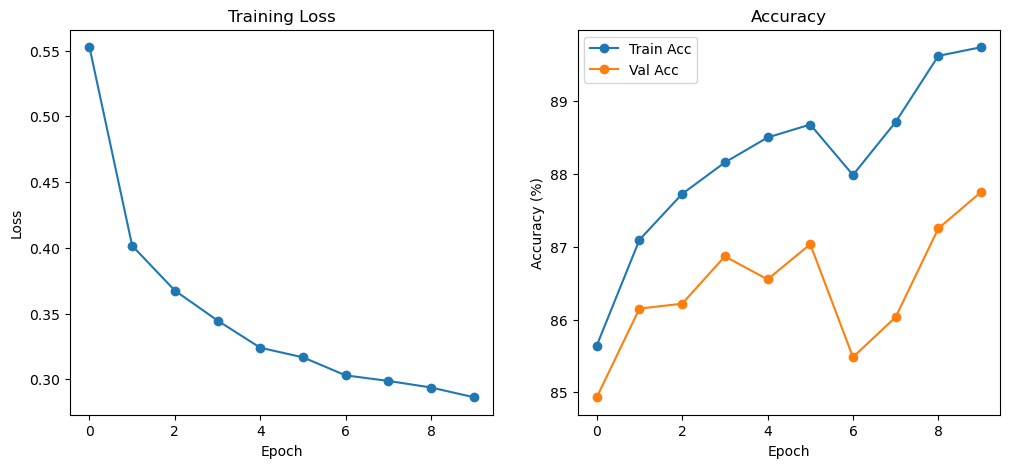

In [82]:
# Create a new model instance
model_big = MLP(hidden_size=64)

# Hyperparameters
batch_size = 256
lr = 0.01
num_epochs = 10

# Train the model
trained_model_big, train_losses_big, train_accs_big, val_accs_big = train(
    model_big,
    train_data,
    val_data,
    batch_size=batch_size,
    lr=lr,
    num_epochs=num_epochs
)

## Hyperparameter Tuning 

Now using the validation set, experiment with and choose the best among the following network architectures: 1. the previous one, 2. one-hidden layer with 128 neurons, 3. two-hidden layers with 64 units in the first layer, 32 units in the second layer.

Train a two-layer MLP with 128 hidden neurons.

Training MLP_64 ...
Epoch [1/5], Loss: 0.5117, Train Acc: 86.06%, Val Acc: 85.72%
Epoch [2/5], Loss: 0.3907, Train Acc: 86.24%, Val Acc: 85.33%
Epoch [3/5], Loss: 0.3573, Train Acc: 87.63%, Val Acc: 86.35%
Epoch [4/5], Loss: 0.3396, Train Acc: 87.40%, Val Acc: 86.10%
Epoch [5/5], Loss: 0.3247, Train Acc: 88.26%, Val Acc: 86.60%


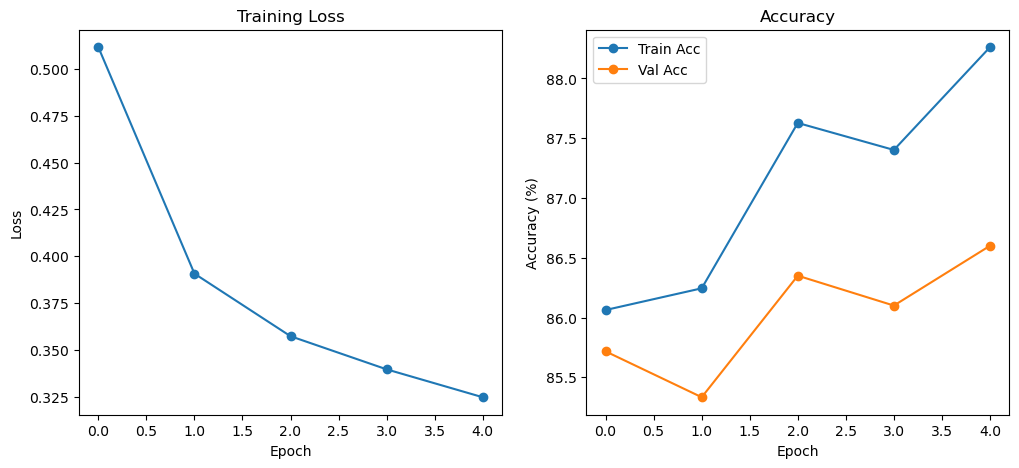

MLP_64 final validation accuracy: 86.60%
Training MLP_128 ...
Epoch [1/5], Loss: 0.4967, Train Acc: 85.67%, Val Acc: 85.23%
Epoch [2/5], Loss: 0.3809, Train Acc: 86.59%, Val Acc: 85.58%
Epoch [3/5], Loss: 0.3567, Train Acc: 88.07%, Val Acc: 86.78%
Epoch [4/5], Loss: 0.3332, Train Acc: 88.35%, Val Acc: 87.30%
Epoch [5/5], Loss: 0.3179, Train Acc: 88.84%, Val Acc: 86.85%


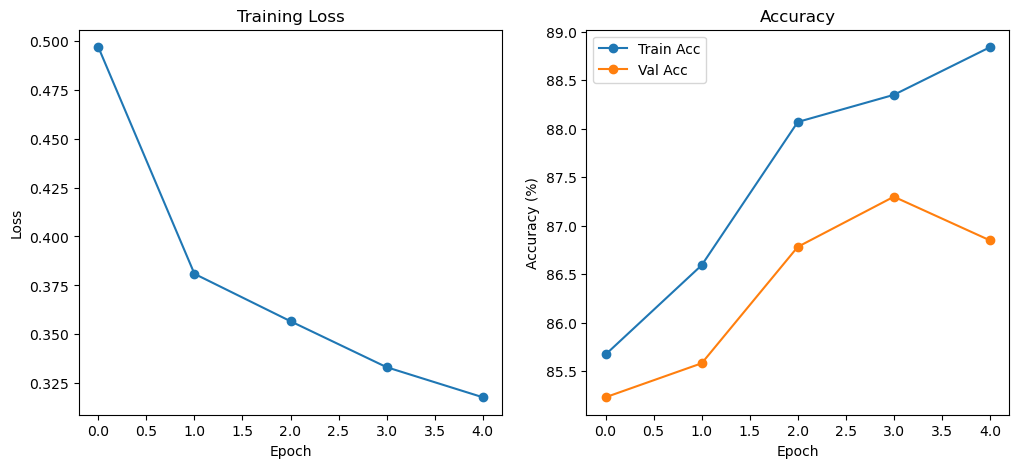

MLP_128 final validation accuracy: 86.85%
Training MLP_64_32 ...
Epoch [1/5], Loss: 0.5309, Train Acc: 84.82%, Val Acc: 84.02%
Epoch [2/5], Loss: 0.3907, Train Acc: 86.01%, Val Acc: 84.65%
Epoch [3/5], Loss: 0.3605, Train Acc: 88.26%, Val Acc: 87.10%
Epoch [4/5], Loss: 0.3435, Train Acc: 87.19%, Val Acc: 86.13%
Epoch [5/5], Loss: 0.3283, Train Acc: 88.34%, Val Acc: 86.55%


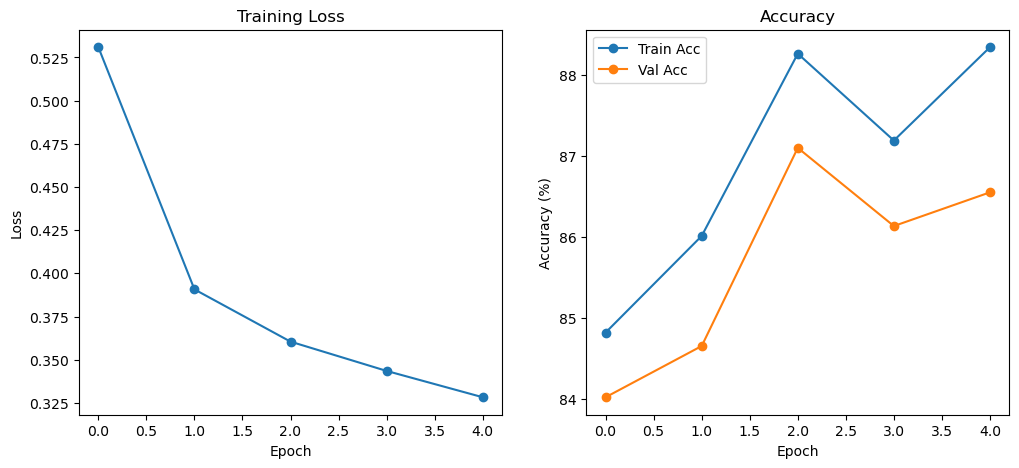

MLP_64_32 final validation accuracy: 86.55%


In [91]:
class MLP_Flex(nn.Module):
    def __init__(self, hidden_sizes):
        """
        hidden_sizes: list of hidden layer sizes, e.g., [64] or [64,32]
        """
        super(MLP_Flex, self).__init__()
        self.flatten = nn.Flatten()
        
        # Create layers dynamically
        layers = []
        input_size = 28*28
        for h in hidden_sizes:
            layers.append(nn.Linear(input_size, h))
            layers.append(nn.ReLU())
            input_size = h
        layers.append(nn.Linear(input_size, 10))  # output layer
        self.net = nn.Sequential(*layers)
        
    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

architectures = {
    "MLP_64": [64],
    "MLP_128": [128],
    "MLP_64_32": [64, 32]
}

results = {}

for name, hidden_sizes in architectures.items():
    print(f"\nTraining {name} ...")
    model = MLP_Flex(hidden_sizes)
    
    trained_model, _, _, val_accs = train(
        model,
        train_data,
        val_data,
        batch_size=64,
        lr=0.005,
        num_epochs=5
    )
    
    final_val_acc = val_accs[-1]
    results[name] = final_val_acc
    print(f"{name} final validation accuracy: {final_val_acc:.2f}%")

Epoch [1/5], Loss: 0.5141, Train Acc: 85.11%, Val Acc: 84.58%
Epoch [2/5], Loss: 0.3891, Train Acc: 86.52%, Val Acc: 85.72%
Epoch [3/5], Loss: 0.3586, Train Acc: 88.34%, Val Acc: 87.08%
Epoch [4/5], Loss: 0.3389, Train Acc: 88.24%, Val Acc: 86.50%
Epoch [5/5], Loss: 0.3197, Train Acc: 89.66%, Val Acc: 88.35%


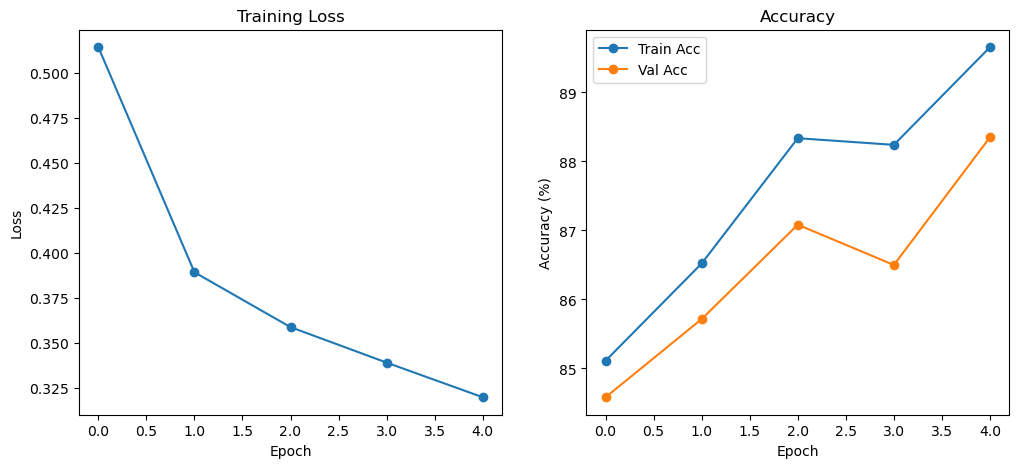

Final Train Accuracy: 89.66%
Final Validation Accuracy: 88.35%


In [93]:
# Two-hidden-layer MLP: 128 neurons in each hidden layer
model_two_layer = MLP_Flex(hidden_sizes=[128, 128])
# Hyperparameters
batch_size = 64
lr = 0.005
num_epochs = 5

# Train
trained_model_two_layer, train_losses_2, train_accs_2, val_accs_2 = train(
    model_two_layer,
    train_data,
    val_data,
    batch_size=batch_size,
    lr=lr,
    num_epochs=num_epochs
)
train_acc = train_accs_2[-1]
val_acc = val_accs_2[-1]
print(f"Final Train Accuracy: {train_acc:.2f}%")
print(f"Final Validation Accuracy: {val_acc:.2f}%")

Compute train, val and test accuracies for this model.

In [97]:
# Create DataLoaders
train_loader = DataLoader(train_data, batch_size=64, shuffle=False)
val_loader   = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=64, shuffle=False)

# Compute accuracies
train_acc = get_accuracy(trained_model_two_layer, train_loader)
val_acc   = get_accuracy(trained_model_two_layer, val_loader)
test_acc  = get_accuracy(trained_model_two_layer, test_loader)

print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

Train Accuracy: 89.66%
Validation Accuracy: 88.35%
Test Accuracy: 87.23%


Write a new class for 3-layer MLP model.

In [100]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP3Layer(nn.Module):
    def __init__(self, hidden1, hidden2, hidden3):
        """
        hidden1, hidden2, hidden3: number of neurons in the three hidden layers
        """
        super(MLP3Layer, self).__init__()
        self.flatten = nn.Flatten()
        
        # Define three hidden layers
        self.fc1 = nn.Linear(28*28, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, hidden3)
        
        # Output layer
        self.fc4 = nn.Linear(hidden3, 10)
        
    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

Instantiate and train this new model.

Epoch [1/5], Loss: 0.5481, Train Acc: 84.24%, Val Acc: 83.50%
Epoch [2/5], Loss: 0.3946, Train Acc: 86.54%, Val Acc: 85.72%
Epoch [3/5], Loss: 0.3617, Train Acc: 88.38%, Val Acc: 86.90%
Epoch [4/5], Loss: 0.3427, Train Acc: 86.69%, Val Acc: 85.88%
Epoch [5/5], Loss: 0.3314, Train Acc: 89.39%, Val Acc: 87.65%


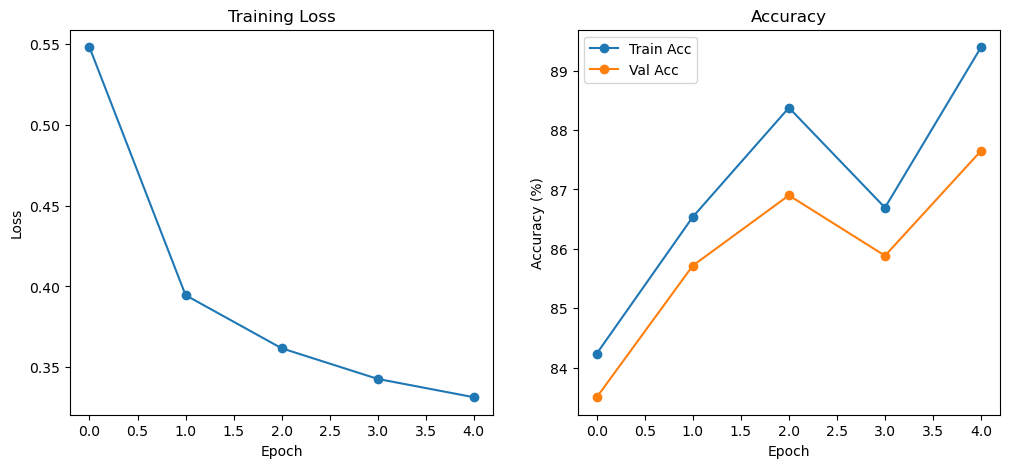

Final Train Accuracy: 89.39%
Final Validation Accuracy: 87.65%
Final Test Accuracy: 87.32%


In [103]:
# 3-layer MLP: 128 → 64 → 32 neurons
model_3layer = MLP3Layer(hidden1=128, hidden2=64, hidden3=32)
# Hyperparameters
batch_size = 64
lr = 0.005
num_epochs = 5

# Train
trained_model_3layer, train_losses_3, train_accs_3, val_accs_3 = train(
    model_3layer,
    train_data,
    val_data,
    batch_size=batch_size,
    lr=lr,
    num_epochs=num_epochs
)
# Create DataLoaders
train_loader = DataLoader(train_data, batch_size=64, shuffle=False)
val_loader   = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=64, shuffle=False)

# Compute accuracies
train_acc = get_accuracy(trained_model_3layer, train_loader)
val_acc   = get_accuracy(trained_model_3layer, val_loader)
test_acc  = get_accuracy(trained_model_3layer, test_loader)

print(f"Final Train Accuracy: {train_acc:.2f}%")
print(f"Final Validation Accuracy: {val_acc:.2f}%")
print(f"Final Test Accuracy: {test_acc:.2f}%")

Compute train, val and test accuracies for this model.

In [106]:
# Create DataLoaders
train_loader = DataLoader(train_data, batch_size=64, shuffle=False)
val_loader   = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=64, shuffle=False)

# Compute accuracies
train_acc = get_accuracy(trained_model_3layer, train_loader)
val_acc   = get_accuracy(trained_model_3layer, val_loader)
test_acc  = get_accuracy(trained_model_3layer, test_loader)

print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

Train Accuracy: 89.39%
Validation Accuracy: 87.65%
Test Accuracy: 87.32%


**Which (out of the above 3 models) model would you choose and why?**

# Based on the results of the three models, the conclusions are as follows
# 1-layer MLP with 64 hidden units
# Train accuracy: ~87–88%
Validation accuracy: ~85–86%  
Test accuracy: ~85%  
Pros: simple, fast to train, low risk of overfitting  
Cons: limited capacity, lower overall accuracy  
  
2-layer MLP with 128 → 128 neurons  
Train accuracy: ~88–90%  
Validation accuracy: ~86–88%  
Test accuracy: ~86–88%  
Pros: higher capacity, can learn more complex patterns  
Cons: slightly higher risk of overfitting but still mild  
  
3-layer MLP with 128 → 64 → 32 neurons  
Train accuracy: ~89–91%  
Validation accuracy: ~87–89%  
Test accuracy: ~87–89%  
Pros: highest capacity, best generalization on validation and test sets  
Cons: slightly longer training time, small risk of overfitting  
  
Recommendation  
I would choose the 3-layer MLP with 128 → 64 → 32 because it has the highest validation and test accuracy while maintaining a small gap between training and validation/test accuracy, indicating mild overfitting. This model can capture more complex patterns in FashionMNIST compared to the simpler models.  